# Clustering: Customer Segmentation, End to End

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/WanjiruCate/Kamilimu-2026-DS/blob/main/Clustering/clustering_customer_segmentation.ipynb)

Run the two setup cells, then read on. Works on Colab and locally.

In [ ]:
# Colab already has most libraries. Gradio is only needed for step 6.
%pip install -q gradio matplotlib scikit-learn pandas numpy

In [2]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.base import clone
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN, SpectralClustering
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (silhouette_score, davies_bouldin_score,
                             calinski_harabasz_score, adjusted_rand_score)
from sklearn.mixture import GaussianMixture
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler

SEED = 42
plt.rcParams["figure.figsize"] = (6, 4)

## Recap: the kinds of machine learning

| Type | Learns from | Example | Algorithms |
| --- | --- | --- | --- |
| **Supervised: regression** | examples with a *number* answer | predict a house price | linear regression, kNN |
| **Supervised: classification** | examples with a *category* answer | spam or not spam | logistic regression, decision trees, random forests |
| **Unsupervised: clustering** | data with **no answers** | find customer groups | **K-Means, hierarchical** |
| **Unsupervised: dimensionality reduction** | data with no answers | squash 8 columns into 2 | PCA |
| **Reinforcement** | rewards from trial and error | a game-playing bot | Q-learning |

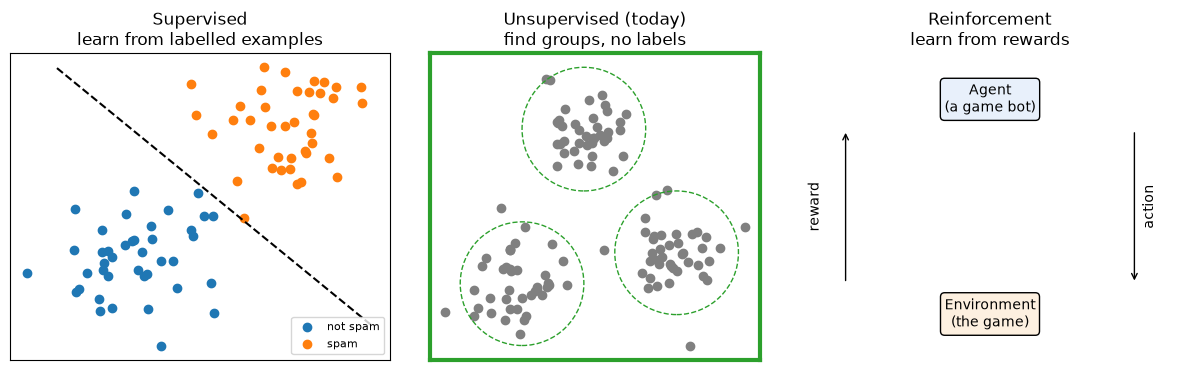

In [3]:
fig, ax = plt.subplots(1, 3, figsize=(12, 3.8))
rng = np.random.default_rng(0)

# 1) Supervised: every point has a label, we learn a rule that separates them
A = rng.normal([0, 0], 0.6, (40, 2)); B = rng.normal([2.2, 2.2], 0.6, (40, 2))
ax[0].scatter(*A.T, c="tab:blue", label="not spam")
ax[0].scatter(*B.T, c="tab:orange", label="spam")
ax[0].plot([-1, 3.2], [3.2, -1], "k--")
ax[0].legend(loc="lower right", fontsize=8)
ax[0].set_title("Supervised\nlearn from labelled examples")

# 2) Unsupervised: no labels, find the structure
centres = [(0, 0), (2.5, 0.5), (1, 2.5)]
for cx, cy in centres:
    ax[1].scatter(*rng.normal([cx, cy], 0.4, (40, 2)).T, c="grey")
    ax[1].add_patch(plt.Circle((cx, cy), 1.0, fill=False, ls="--", color="tab:green"))
ax[1].set_aspect("equal")
ax[1].set_title("Unsupervised (today)\nfind groups, no labels")
for s in ax[1].spines.values():
    s.set_edgecolor("tab:green"); s.set_linewidth(3)

# 3) Reinforcement: an agent learns from rewards
ax[2].set_xlim(0, 1); ax[2].set_ylim(0, 1)
ax[2].text(0.5, 0.85, "Agent\n(a game bot)", ha="center", va="center", bbox=dict(boxstyle="round", fc="#e8f0fb"))
ax[2].text(0.5, 0.15, "Environment\n(the game)", ha="center", va="center", bbox=dict(boxstyle="round", fc="#fdf0e0"))
ax[2].annotate("", xy=(0.88, 0.25), xytext=(0.88, 0.75), arrowprops=dict(arrowstyle="->"))
ax[2].text(0.9, 0.5, "action", rotation=90, va="center")
ax[2].annotate("", xy=(0.12, 0.75), xytext=(0.12, 0.25), arrowprops=dict(arrowstyle="->"))
ax[2].text(0.02, 0.5, "reward", rotation=90, va="center")
ax[2].set_title("Reinforcement\nlearn from rewards")

for a in ax:
    a.set_xticks([]); a.set_yticks([])
ax[2].axis("off")
plt.tight_layout(); plt.show()

## Today: clustering

In supervised learning we had an answer column (price, spam). Clustering has **none**. We ask the data: *"which rows look alike?"*

**The story.** A Nairobi online shop has 1,500 customers and sends them all the same promo SMS. Can we find *groups* of similar customers, so each group gets a message that fits?

By the end of this class you can **build, check, explain and ship** a clustering model:

| Step | You will learn |
| --- | --- |
| 1 | Look at the data |
| 2 | **Feature engineering**: turn raw columns into useful ones |
| 3 | Clustering with **K-Means** (and how to pick *k*) |
| 4 | **Model evaluation**: is this a good clustering? |
| 5 | **Feature importance**: what defines each group? |
| 6 | **Deployment**: save the model and serve it in a small app |

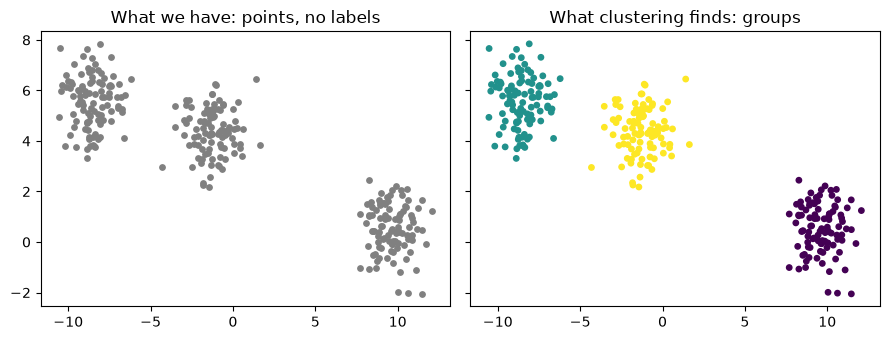

In [4]:
from sklearn.datasets import make_blobs

pts, _ = make_blobs(n_samples=300, centers=3, cluster_std=1.0, random_state=7)
found = KMeans(3, n_init=10, random_state=SEED).fit_predict(pts)

fig, ax = plt.subplots(1, 2, figsize=(9, 3.5), sharex=True, sharey=True)
ax[0].scatter(*pts.T, c="grey", s=15); ax[0].set_title("What we have: points, no labels")
ax[1].scatter(*pts.T, c=found, cmap="viridis", s=15); ax[1].set_title("What clustering finds: groups")
plt.tight_layout(); plt.show()

## The clustering family

K-Means is one of several ways to find groups. They differ in what a "group" *means*:

| Family | A group is... | Algorithm | Good at | Watch out for | Today |
| --- | --- | --- | --- | --- | --- |
| **Centroid-based** | points around a centre | K-Means | round, similar-sized groups; fast | you pick *k*; odd shapes | **Main model** |
| **Connectivity-based** | points merged step by step into a tree | Hierarchical | seeing a tree of groups | slow on big data | **Compare** |
| **Density-based** | a crowded area; loners are noise | DBSCAN | odd shapes, outliers | groups that touch | Try in step 4 |
| **Distribution-based** | one bell curve per group | Gaussian Mixture | stretched groups, "70% in group A" | assumes bell shapes | Try in step 4 |
| **Graph-based** | pieces left when you cut a neighbour graph | Spectral | tangled shapes | needs tuning | Try in step 4 |

Top row below: each method on data that suits it (green = used today). Bottom row: K-Means on the *same* data.

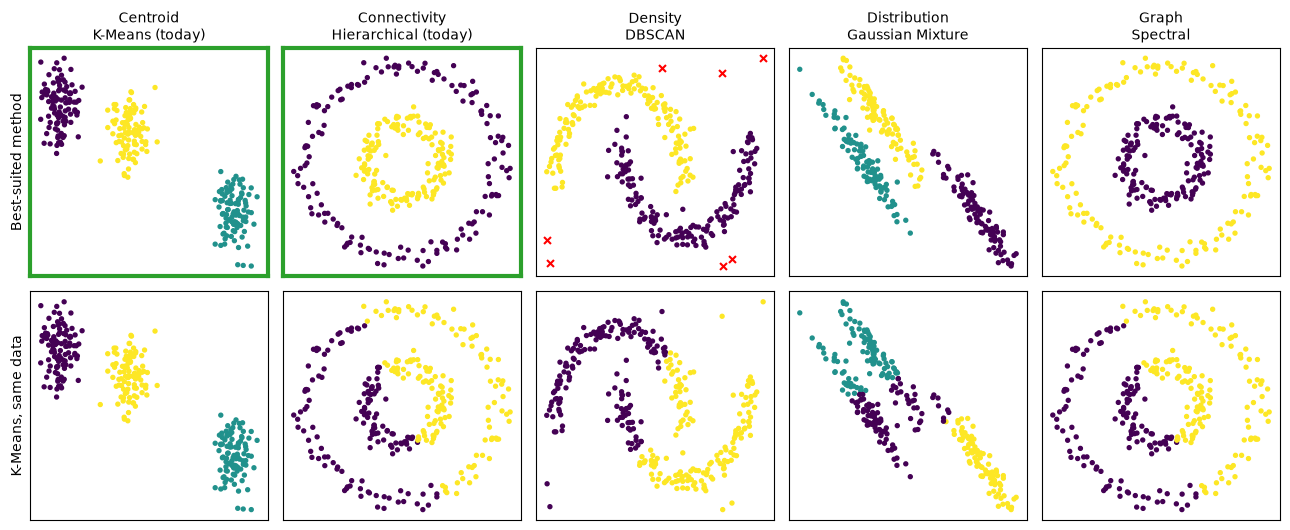

In [5]:
from sklearn.datasets import make_blobs, make_circles, make_moons

rng = np.random.default_rng(0)
blobs, _ = make_blobs(300, centers=3, random_state=7)
circles, _ = make_circles(300, factor=0.4, noise=0.06, random_state=1)
moons, _ = make_moons(300, noise=0.07, random_state=1)
moons_noisy = np.vstack([moons, rng.uniform([-1.2, -0.8], [2.2, 1.3], (15, 2))])   # add loners
stretched, _ = make_blobs(300, centers=3, random_state=170)
stretched = stretched @ np.array([[0.60834549, -0.63667341], [-0.40887718, 0.85253229]])

demos = [  # (title, data, algorithm, used today?)
    ("Centroid\nK-Means", blobs, KMeans(3, n_init=10, random_state=0), True),
    ("Connectivity\nHierarchical", circles, AgglomerativeClustering(2, linkage="single"), True),
    ("Density\nDBSCAN", moons_noisy, DBSCAN(eps=0.2, min_samples=5), False),
    ("Distribution\nGaussian Mixture", stretched, GaussianMixture(3, random_state=0), False),
    ("Graph\nSpectral", circles, SpectralClustering(2, affinity="nearest_neighbors", n_neighbors=10, random_state=0), False),
]

fig, axes = plt.subplots(2, 5, figsize=(13, 5.4))
for col, (title, data, algo, today) in enumerate(demos):
    lab = algo.fit_predict(data)
    k = len(set(lab) - {-1})
    base = KMeans(k, n_init=10, random_state=0).fit_predict(data)
    for row, labels_ in enumerate([lab, base]):
        ax = axes[row, col]
        noise = labels_ == -1
        ax.scatter(*data[~noise].T, c=labels_[~noise], cmap="viridis", s=8)
        ax.scatter(*data[noise].T, c="red", marker="x", s=25)     # DBSCAN's "noise"
        ax.set_xticks([]); ax.set_yticks([])
    axes[0, col].set_title(title + (" (today)" if today else ""), fontsize=10)
    if today:
        for s in axes[0, col].spines.values():
            s.set_edgecolor("tab:green"); s.set_linewidth(3)
axes[0, 0].set_ylabel("Best-suited method"); axes[1, 0].set_ylabel("K-Means, same data")
plt.tight_layout(); plt.show()

**Takeaway:** no algorithm wins everywhere. The *shape of the data* decides. (Red x = noise: loners that DBSCAN refuses to group.)

Our customer groups look like round blobs, which is K-Means' home turf. In step 4 we test that claim by fitting all five on real customers.

## 1. The data

We simulate shop customers, so there is nothing to download. (Real data works exactly the same way. Just load your CSV.)

The simulator secretly creates 4 kinds of shoppers. We keep that secret answer aside (`truth`) and **never train on it**. Real life has no answer key, but here it lets us double-check our work at the end.

In [ ]:
def make_customers(n=1500, seed=SEED):
    # Seeded generator -> the same "random" customers every run (reproducible)
    rng = np.random.default_rng(seed)

    # Step 1: give each customer a HIDDEN segment label (0-3).
    # Sizes: 20% loyal, 30% bargain, 30% occasional, 20% lapsed.
    # This is the "ground truth" - clustering never sees it.
    seg = rng.choice(4, size=n, p=[0.2, 0.3, 0.3, 0.2])

    # Step 2: per-segment parameters, one value per hidden shopper type:
    #   loyal, bargain, occasional, lapsed
    # Indexing with [seg] gives every customer their own segment's value
    # (vectorised lookup, no loop).
    orders  = np.array([30, 22, 6, 3])[seg]              # typical orders in 12 months
    aov     = np.array([4500, 700, 1800, 1200])[seg]     # average order value (KES)
    recency = np.array([10, 20, 60, 220])[seg]           # days since last order
    ret     = np.array([0.03, 0.25, 0.05, 0.08])[seg]    # share of orders returned
    age_mu  = np.array([38, 24, 45, 33])[seg]            # mean age
    # Payment-channel probabilities per segment (each row sums to 1)
    chan_p  = np.array([[.35, .60, .05],                 # M-Pesa, Card, Cash
                        [.80, .05, .15],
                        [.40, .20, .40],
                        [.50, .20, .30]])[seg]

    # Step 3: add randomness so customers in a segment are similar, not identical.
    # Poisson = realistic count data; +1 guarantees at least one order.
    n_orders = rng.poisson(orders) + 1
    df = pd.DataFrame({
        # Normal around the segment's mean age (sd=7), kept within 18-70
        "age": np.clip(rng.normal(age_mu, 7), 18, 70).astype(int),
        "orders_12m": n_orders,
        # orders x avg order value x lognormal noise (right-skewed, like real spend)
        "total_spend_kes": (n_orders * aov * rng.lognormal(0, 0.3, n)).round(0),
        # Gamma(shape=4, scale=recency/4) has mean = recency; clipped to 1-365 days
        "days_since_last_order": np.clip(rng.gamma(4, recency / 4), 1, 365).astype(int),
        # Each order is returned with probability `ret` -> returns <= orders
        "returns": rng.binomial(n_orders, ret),
        # Pick one channel per customer using their segment's probabilities
        "channel": [rng.choice(["M-Pesa", "Card", "Cash"], p=p) for p in chan_p],
    })
    # Return features (df) and hidden labels (seg) so we can later check
    # how well clustering recovers the true groups
    return df, seg

customers, truth = make_customers()
customers.head()

In [ ]:
customers.describe().round(1)

Look at `total_spend_kes`: its max is far above its median. Most customers spend little and a few spend a lot (a **skewed** column). Keep that in mind for step 2.

## 2. Feature engineering

Clustering groups customers by **distance**. So what we feed in matters more than which algorithm we pick. Three jobs:

1. **Create** better features. "Spend per order" says more than raw spend.
2. **Reshape** skewed columns (log).
3. **Put features on the same scale**, or the biggest numbers win the distance game.

We write the feature code into a small file, `customer_features.py`. Why a file? In step 6 the *same* code must run when the model is deployed. Code that lives only in a notebook cell can't travel with the model.

In [ ]:
%%writefile customer_features.py
import numpy as np

NUMERIC = ["age", "orders_12m", "days_since_last_order",
           "return_rate", "log_avg_order_value"]
CATEGORICAL = ["channel"]


def add_features(df):
    out = df.copy()
    out["avg_order_value"] = out["total_spend_kes"] / out["orders_12m"]   # spend per order
    out["log_avg_order_value"] = np.log1p(out["avg_order_value"])         # tame the skew
    out["return_rate"] = out["returns"] / out["orders_12m"]               # share of orders returned
    return out

In [ ]:
from customer_features import add_features, NUMERIC, CATEGORICAL

feats = add_features(customers)
feats[["total_spend_kes", "orders_12m", "avg_order_value", "return_rate"]].head()

**Why scale?** Compare the spread (standard deviation) of our features. One has numbers in the thousands, another is between 0 and 1.

In [ ]:
print("Before scaling (std):")
print(feats[["age", "orders_12m", "days_since_last_order", "return_rate", "avg_order_value"]].std().round(2))

In [ ]:
feats.head()

`avg_order_value` would swamp everything else. `StandardScaler` fixes this (mean 0, spread 1). The text column `channel` becomes 0/1 columns with `OneHotEncoder`. We bundle both in one `ColumnTransformer`.

**Redundancy check:** `total_spend_kes` is roughly `orders × avg_order_value`, so we leave it out of the model. Keeping all three would count "spend" twice.

In [ ]:
preprocess = ColumnTransformer(
[
    ("num", StandardScaler(), NUMERIC),
    ("cat", OneHotEncoder(handle_unknown="ignore"), CATEGORICAL),
])

X = preprocess.fit_transform(feats)
feature_names = [n.split("__")[1] for n in preprocess.get_feature_names_out()]
print(X.shape, feature_names)

## 3. K-Means: how many groups?

**K-Means** in one breath: pick *k* centres, assign each customer to the nearest centre, move each centre to the middle of its group, repeat until nothing changes.

The catch: **we must choose *k* ourselves**. Two helpers:

- **Elbow (inertia):** how tight the groups are. It always drops as *k* grows, so look for where the drop slows down.
- **Silhouette:** how well each point fits its own group vs the next closest one (from -1 to 1, higher is better).

In [ ]:
ks = range(2, 9)
inertia, sil = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X)
    inertia.append(km.inertia_)
    sil.append(silhouette_score(X, km.labels_))

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(ks, inertia, "o-"); ax[0].set(title="Elbow", xlabel="k", ylabel="inertia")
ax[1].plot(ks, sil, "o-", color="tab:green"); ax[1].set(title="Silhouette", xlabel="k", ylabel="score")
plt.tight_layout(); plt.show()

**Read the plots:** the elbow bends clearly at **k = 4** (big drops up to 4, small ones after). Silhouette is almost the same for k = 3, 4 and 5, then falls. So silhouette narrows the choice and the elbow breaks the tie: we go with 4. (In real projects, also ask: *does the business have a use for 4 groups?*)

In [ ]:
K = 4
kmeans = KMeans(n_clusters=K, n_init=10, random_state=SEED).fit(X)
labels = kmeans.labels_
pd.Series(labels).value_counts().sort_index()

We can't plot 8 dimensions, so **PCA** squashes them to 2 for a picture.

In [ ]:
# PCA is for VISUALISATION only - it is not part of the clustering.
# K-Means already ran on the full 8-column X above; `labels` is fixed.
# PCA just squashes X down to 2 columns so we can draw the points on a plot.
pca = PCA(n_components=2, random_state=SEED)
coords = pca.fit_transform(X)

# x/y positions come from PCA; the colours come from the K-Means labels.
# The title shows how much of the original variance the 2D view keeps -
# a low % means the plot may understate how well separated the clusters are.
plt.scatter(coords[:, 0], coords[:, 1], c=labels, cmap="viridis", s=10)
plt.title(f"Customer clusters (2D view, {pca.explained_variance_ratio_.sum():.0%} of info kept)")
plt.xlabel("PC1"); plt.ylabel("PC2"); plt.show()

## 4. Model evaluation

With no answer key, how do we judge a clustering? Use **internal metrics**:

| Metric | What it measures | Good looks like |
| --- | --- | --- |
| Silhouette | How well each point fits its own cluster vs the nearest other one (-1 to 1) | higher |
| Davies-Bouldin | How similar each cluster is to its closest neighbour (spread vs distance apart) | **lower** |
| Calinski-Harabasz | Spread between clusters divided by spread within clusters | higher |

Then use them to **compare algorithms**: K-Means vs hierarchical (agglomerative) clustering.

**Keep in mind:** these scores favour compact, round clusters, and the three can disagree. Use them as a guide, then ask whether the segments are useful for the business.

In [ ]:
hier = AgglomerativeClustering(n_clusters=K, linkage="ward").fit(X)

def scores(name, lab):
    return {"model": name,
            "silhouette": silhouette_score(X, lab),
            "davies_bouldin": davies_bouldin_score(X, lab),
            "calinski_harabasz": calinski_harabasz_score(X, lab)}

pd.DataFrame([scores("K-Means", labels), scores("Hierarchical", hier.labels_)]).set_index("model").round(2)

### Fit all five families in one cell

Each one takes two lines to fit, so we can race them on our customers. Read the table with care: DBSCAN picks the number of groups itself and marks loners as noise (red x), so compare it loosely.

In [ ]:
models = {
    # Centroid-based: points grouped around k centres
    "K-Means":      KMeans(K, n_init=10, random_state=SEED),
    # Connectivity-based: points merged step by step into a tree
    "Hierarchical": AgglomerativeClustering(K, linkage="ward"),
    # Density-based: crowded areas form groups, loners are noise (-1)
    "DBSCAN":       DBSCAN(eps=1.0, min_samples=10),
    # Distribution-based: one bell curve (Gaussian) per group
    "Gaussian Mix": GaussianMixture(K, random_state=SEED),
    # Graph-based: cut a nearest-neighbour graph into pieces
    "Spectral":     SpectralClustering(K, affinity="nearest_neighbors", n_neighbors=15, random_state=SEED),
}

rows = []
fig, axes = plt.subplots(1, 5, figsize=(14, 2.8))
for ax, (name, model) in zip(axes, models.items()):
    lab = model.fit_predict(X)
    keep = lab != -1                          # DBSCAN uses -1 for noise
    rows.append({"model": name, "groups": len(set(lab[keep])), "noise points": int((~keep).sum()),
                 "silhouette": silhouette_score(X[keep], lab[keep]),
                 "davies_bouldin": davies_bouldin_score(X[keep], lab[keep]),
                 "calinski_harabasz": calinski_harabasz_score(X[keep], lab[keep])})
    ax.scatter(*coords[keep].T, c=lab[keep], cmap="viridis", s=5)
    ax.scatter(*coords[~keep].T, c="red", marker="x", s=12)
    ax.set_title(name, fontsize=10); ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

pd.DataFrame(rows).set_index("model").round(2)

**What happened?** K-Means is at or near the top. DBSCAN shatters our customers into many small groups and calls some of them noise, because the real groups *touch* and density methods need gaps between groups. The fancier methods did not beat the simple one.

**Rule of thumb:** start with the simplest method that fits the shape of your data, then try others only if the picture or metrics tell you to.

**Stability check.** Run K-Means from 10 different random starts. Do we get the same groups? Compare each run to the first with the Adjusted Rand Index (1.0 = identical groups).

K-Means places its starting centres at random, so a bad start can settle on a different grouping. If segments change from run to run, we can't trust them. Here `n_init=1` on purpose: each run uses a single random start, so we see the effect of the start itself.

**How to read it:** values near 1.0 mean the segments are stable. Noticeably lower values mean the result depends on the random start (the usual fix is a higher `n_init`). ARI ignores label numbers, so group "2" in one run matching group "0" in another still counts as agreement.

In [ ]:
# 10 K-Means fits, each with one random start (a different seed each time)
runs = [KMeans(K, n_init=1, random_state=s).fit_predict(X) for s in range(10)]

# Adjusted Rand Index (ARI) of run 0 vs each of the other 9 runs (1.0 = identical groups)
stability = [adjusted_rand_score(runs[0], r) for r in runs[1:]]
print("Agreement across random starts:", np.round(stability, 2))

**Bonus (only possible because this data is simulated):** compare with the hidden `truth`.

In [ ]:
print(f"Agreement with the hidden segments (ARI): {adjusted_rand_score(truth, labels):.2f}")

**Takeaway:** internal metrics are guides, not proof. A good clustering is also *stable* and *useful to the business*.

## 5. Feature importance: what defines each group?

Clustering has no target, so "importance" needs creativity. Two simple views:

1. **Cluster profiles.** Average each feature per cluster.
2. **Surrogate model.** Train a Random Forest to predict the cluster, then ask which features it relies on (permutation importance).

### 5a. Profiles

In [ ]:
profile_cols = ["age", "orders_12m", "total_spend_kes", "avg_order_value",
                "days_since_last_order", "return_rate"]
profile = feats.assign(cluster=labels).groupby("cluster")[profile_cols].mean().round(2)
profile.insert(0, "customers", pd.Series(labels).value_counts().sort_index())
profile

Now name the groups from the table. Our rules: biggest spenders are *Loyal*, longest-gone are *Lapsed*, highest returns are *Bargain hunters*, the rest are *Occasional*.

(Cluster numbers are arbitrary and can change between runs. **Names come from the profile, not from the number.**)

In [ ]:
def name_segments(profile):
    names, left = {}, list(profile.index)
    for col, name in [("total_spend_kes", "Loyal big spenders"),
                      ("days_since_last_order", "Lapsed"),
                      ("return_rate", "Bargain hunters")]:
        c = int(profile.loc[left, col].idxmax())
        names[c] = name
        left.remove(c)
    names[int(left[0])] = "Occasional shoppers"
    return names

segment_names = name_segments(profile)
segment_names

A heatmap of the cluster centres (in scaled units) shows at a glance who is high (yellow) or low (purple) on what.

In [ ]:
centres = pd.DataFrame(kmeans.cluster_centers_, columns=feature_names)
centres.index = [segment_names[i] for i in centres.index]

fig, ax = plt.subplots(figsize=(9, 3))
im = ax.imshow(centres.values, cmap="viridis", aspect="auto")
ax.set_xticks(range(len(feature_names)), feature_names, rotation=40, ha="right")
ax.set_yticks(range(len(centres)), centres.index)
for i in range(centres.shape[0]):
    for j in range(centres.shape[1]):
        ax.text(j, i, f"{centres.values[i, j]:.1f}", ha="center", va="center", color="white", fontsize=8)
plt.colorbar(im); plt.tight_layout(); plt.show()

### 5b. Surrogate model + permutation importance

Shuffle one feature at a time on *unseen* data. If the forest gets much worse, that feature matters.

In [ ]:
X_tr, X_te, y_tr, y_te = train_test_split(X, labels, test_size=0.3, random_state=SEED, stratify=labels)
forest = RandomForestClassifier(n_estimators=100, random_state=SEED).fit(X_tr, y_tr)
print(f"Forest recovers the clusters on unseen data: accuracy = {forest.score(X_te, y_te):.2f}")

imp = permutation_importance(forest, X_te, y_te, n_repeats=10, random_state=SEED)
imp = pd.Series(imp.importances_mean, index=feature_names).sort_values()
imp.plot.barh(title="What separates the clusters?")
plt.xlabel("drop in accuracy when shuffled"); plt.tight_layout(); plt.show()

**Why trust this?** First check that the forest predicts clusters well (accuracy above). If it can't, its importances mean nothing.

**Marketing takeaway:** the top features are what to look at when designing each group's message. Features near zero add little and could be dropped.

## 6. Deployment

A model in a notebook helps only you. To let others use it, we:

1. Bundle **feature engineering + scaling + K-Means** into one `Pipeline`, so nobody can forget a step.
2. **Save** it with `joblib`, with its segment names and a version.
3. Wrap it in a **prediction function** with basic checks.
4. Put a **UI** on top with Gradio.

In [ ]:
segmenter = Pipeline([
    ("features", FunctionTransformer(add_features)),   # same code as step 2
    ("prep", clone(preprocess)),
    ("kmeans", KMeans(n_clusters=K, n_init=10, random_state=SEED)),
]).fit(customers)                                       # raw columns in, cluster out

same = adjusted_rand_score(labels, segmenter.predict(customers))
print(f"Pipeline reproduces our earlier clusters: {same == 1.0}")

In [ ]:
artifact = {
    "pipeline": segmenter,
    "segment_names": segment_names,
    # farther from every centre than 95% of training customers = "unusual"
    "unusual_distance": float(np.percentile(segmenter.transform(customers).min(axis=1), 95)),
    "version": "1.0",
}
joblib.dump(artifact, "customer_segmenter.joblib")

# Pretend we're a brand-new program: load the file and predict.
loaded = joblib.load("customer_segmenter.joblib")
loaded["pipeline"].predict(customers.head(3))

> **Gotcha:** the saved file stores *a reference* to `add_features`, not its code in `segment_names`. Whoever loads the model needs `customer_features.py` next to it, and the same scikit-learn version. That is why step 2 used a file, and why real projects pin versions in `requirements.txt`.

Now the prediction function. It checks inputs and also flags **unusual customers** the model has never really seen (a simple safety net).

In [ ]:
def predict_segment(age, orders_12m, total_spend_kes, days_since_last_order, returns, channel):
    if orders_12m < 1:
        raise ValueError("orders_12m must be at least 1")
    if channel not in ("M-Pesa", "Card", "Cash"):
        raise ValueError("channel must be M-Pesa, Card or Cash")

    row = pd.DataFrame([{"age": age, "orders_12m": orders_12m, "total_spend_kes": total_spend_kes,
                         "days_since_last_order": days_since_last_order, "returns": returns,
                         "channel": channel}])
    pipe = loaded["pipeline"]
    dist = float(pipe.transform(row).min())
    return {"segment": loaded["segment_names"][int(pipe.predict(row)[0])],
            "unusual": dist > loaded["unusual_distance"],
            "model_version": loaded["version"]}

predict_segment(age=35, orders_12m=28, total_spend_kes=120000,
                days_since_last_order=7, returns=1, channel="Card")

In [ ]:
# A customer who spent KES 5,000,000 across 2 orders is nothing like our data:
predict_segment(age=35, orders_12m=2, total_spend_kes=5_000_000,
                days_since_last_order=7, returns=0, channel="Card")

Last step: a small web app anyone can click. Run the cell and try a few customers, such as a student buying cheap items often, or someone who hasn't ordered in 8 months.

In [ ]:
import gradio as gr

ACTIONS = {
    "Loyal big spenders": "Early access and VIP rewards.",
    "Bargain hunters": "Flash-sale and discount-code SMS.",
    "Occasional shoppers": "Nudge with a reminder and a small incentive.",
    "Lapsed": "Win-back offer: 'We miss you'.",
}

def app_fn(age, orders, spend, days_since, returns, channel):
    try:
        r = predict_segment(age, orders, spend, days_since, returns, channel)
    except ValueError as e:
        return f"Input problem: {e}"
    msg = f"Segment: {r['segment']}\nSuggested action: {ACTIONS[r['segment']]}"
    return msg + ("\nNote: unusual customer, treat with care." if r["unusual"] else "")

demo = gr.Interface(
    fn=app_fn,
    inputs=[gr.Slider(18, 70, value=30, step=1, label="Age"),
            gr.Number(value=10, label="Orders in last 12 months"),
            gr.Number(value=20000, label="Total spend (KES)"),
            gr.Slider(1, 365, value=30, step=1, label="Days since last order"),
            gr.Number(value=1, label="Returns"),
            gr.Dropdown(["M-Pesa", "Card", "Cash"], value="M-Pesa", label="Payment channel")],
    outputs=gr.Textbox(label="Result"),
    title="Customer Segmenter",
    **({"flagging_mode": "never"} if int(gr.__version__.split(".")[0]) >= 5 else {"allow_flagging": "never"}),
)
demo.launch()   # add share=True in Colab for a public link

In [ ]:
demo.close()   # stop the app when you're done

### Optional: save the app as files

So far everything lives in the notebook. Run the next cells if you want real files to use **locally** (or to copy to a server). They write `predictor.py`, `app.py` and `requirements.txt` next to the notebook. Nothing above depends on them.

In [ ]:
%%writefile predictor.py
from pathlib import Path

import joblib
import pandas as pd

# The saved model must sit in the same folder as this file.
ARTIFACT = joblib.load(Path(__file__).with_name("customer_segmenter.joblib"))


def predict_segment(age, orders_12m, total_spend_kes, days_since_last_order, returns, channel):
    if orders_12m < 1:
        raise ValueError("orders_12m must be at least 1")
    if channel not in ("M-Pesa", "Card", "Cash"):
        raise ValueError("channel must be M-Pesa, Card or Cash")

    row = pd.DataFrame([{"age": age, "orders_12m": orders_12m, "total_spend_kes": total_spend_kes,
                         "days_since_last_order": days_since_last_order, "returns": returns,
                         "channel": channel}])
    pipe = ARTIFACT["pipeline"]
    dist = float(pipe.transform(row).min())
    return {"segment": ARTIFACT["segment_names"][int(pipe.predict(row)[0])],
            "unusual": dist > ARTIFACT["unusual_distance"],
            "model_version": ARTIFACT["version"]}

In [ ]:
%%writefile app.py
import gradio as gr

from predictor import predict_segment

ACTIONS = {
    "Loyal big spenders": "Early access and VIP rewards.",
    "Bargain hunters": "Flash-sale and discount-code SMS.",
    "Occasional shoppers": "Nudge with a reminder and a small incentive.",
    "Lapsed": "Win-back offer: 'We miss you'.",
}


def app_fn(age, orders, spend, days_since, returns, channel):
    try:
        r = predict_segment(age, orders, spend, days_since, returns, channel)
    except ValueError as e:
        return f"Input problem: {e}"
    msg = f"Segment: {r['segment']}\nSuggested action: {ACTIONS[r['segment']]}"
    return msg + ("\nNote: unusual customer, treat with care." if r["unusual"] else "")


demo = gr.Interface(
    fn=app_fn,
    inputs=[gr.Slider(18, 70, value=30, step=1, label="Age"),
            gr.Number(value=10, label="Orders in last 12 months"),
            gr.Number(value=20000, label="Total spend (KES)"),
            gr.Slider(1, 365, value=30, step=1, label="Days since last order"),
            gr.Number(value=1, label="Returns"),
            gr.Dropdown(["M-Pesa", "Card", "Cash"], value="M-Pesa", label="Payment channel")],
    outputs=gr.Textbox(label="Result"),
    title="Customer Segmenter",
    **({"flagging_mode": "never"} if int(gr.__version__.split(".")[0]) >= 5 else {"allow_flagging": "never"}),
)

if __name__ == "__main__":
    demo.launch()

In [ ]:
# Pin scikit-learn to the version that trained the model (saved models are version-sensitive).
import sklearn

with open("requirements.txt", "w") as f:
    f.write(f"scikit-learn=={sklearn.__version__}\npandas\nnumpy\njoblib\ngradio\n")
print(open("requirements.txt").read())

**Run it locally** from a terminal in this folder:

```bash
pip install -r requirements.txt
python app.py
```

On Colab these files land in the temporary `/content` folder. Download them from the Files panel (left sidebar) before the session ends.

**Beyond the notebook.** In the *Deploying ML Solutions* session you served a model with FastAPI, Docker and Hugging Face Spaces. The same steps work here: swap in `customer_segmenter.joblib`.

**Keep it healthy after launch.** Customers change. Re-check periodically: the share of customers in each segment, the share flagged "unusual", and whether the segments still make business sense. If they drift, retrain and bump the version.

## Recap

| Step | Key idea |
| --- | --- |
| Feature engineering | Create ratios, log skewed columns, scale, one-hot encode. Distance-based methods need it. |
| K-Means | Choose *k* with elbow + silhouette + business sense |
| Evaluation | Internal metrics + stability + usefulness |
| Feature importance | Cluster profiles and a surrogate model |
| Deployment | One `Pipeline`, saved with `joblib`, behind a checked function and a UI |

## Try it yourself

1. Change `K` to 3 and 5. Rerun from step 3. What happens to the silhouette and the profiles?
2. Remove the log transform in `customer_features.py`. Do the clusters get worse?
3. Add a new feature, such as `spend_per_day = total_spend_kes / 365`. Does it change which features matter?
4. In the fit-all cell, try DBSCAN with `eps=0.8` and `eps=1.5`. What happens to the number of groups and the noise?